# Nonword orthographic ill-formedness

For each nonword this computes the mean over its letters and its end of −ln P(letter | previous letters).
Letter bigram and trigram counts come from CMUdict spellings, with add-one smoothing. The unit is nats per letter,
and higher means less English-like spelling. The list score is the mean over its nonwords (`orthographic_ngram`).

Real words from the example sentences serve as a reference. It needs nothing but CMUdict
(`python -c "import nltk; nltk.download('cmudict')"`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

from linguistic.assemble import run_metrics
from linguistic.io import load_stimuli
from linguistic.normalize import Lexicon, build_units
from linguistic.registry import Context, select

NONWORDS = ROOT / "data/examples/nonwords/stimuli.csv"
REFERENCE = ROOT / "data/examples/sentences/stimuli.csv"     # real words, for comparison

lexicon = Lexicon()

def orthographic(path):
    stimuli = load_stimuli(path)
    units = build_units(stimuli, lexicon)
    return run_metrics(Context(stimuli, units.words, units.phones, lexicon), select(["orthographic"]))

nw, ref = orthographic(NONWORDS), orthographic(REFERENCE)
cols = ["stimulus_id", "word", "orth_bigram_surp", "orth_trigram_surp"]
nw.words[cols].sort_values("orth_trigram_surp").round(3)

,stimulus_id,word,orth_bigram_surp,orth_trigram_surp
9,nonword_list_1,breistel,2.385,2.102
4,nonword_list_1,bermose,2.404,2.214
42,nonword_list_4,trocklude,2.723,2.241
24,nonword_list_3,guebal,2.892,2.338
33,nonword_list_3,parmure,2.475,2.352
44,nonword_list_4,frintase,2.379,2.352
59,nonword_list_5,treinege,2.579,2.376
16,nonword_list_2,hollept,2.668,2.405
10,nonword_list_1,bulnete,2.810,2.442
41,nonword_list_4,selserane,2.303,2.451


## List level: mean over the list's nonwords

In [2]:
nw.stimuli[["stimulus_id", "n_words", "orth_bigram_surp", "orth_trigram_surp"]].round(3)

,stimulus_id,n_words,orth_bigram_surp,orth_trigram_surp
0,nonword_list_1,12,2.702,2.565
1,nonword_list_2,12,2.822,2.858
2,nonword_list_3,12,2.816,2.744
3,nonword_list_4,12,2.670,2.655
4,nonword_list_5,12,2.694,2.739


## Compared with real words

In [3]:
both = pd.concat([nw.words.assign(kind="nonword"), ref.words.assign(kind="real word")])
both["n_letters"] = both["word"].str.lower().str.count("[a-z]")
both.groupby("kind")[["orth_bigram_surp", "orth_trigram_surp", "n_letters"]].agg(["mean", "std"]).round(3)

orth_bigram_surp        orth_trigram_surp        n_letters       
                      mean    std              mean    std      mean    std
kind                                                                       
nonword              2.741  0.240             2.712  0.278     7.967  1.235
real word            2.535  0.301             2.520  0.685     3.931  1.576

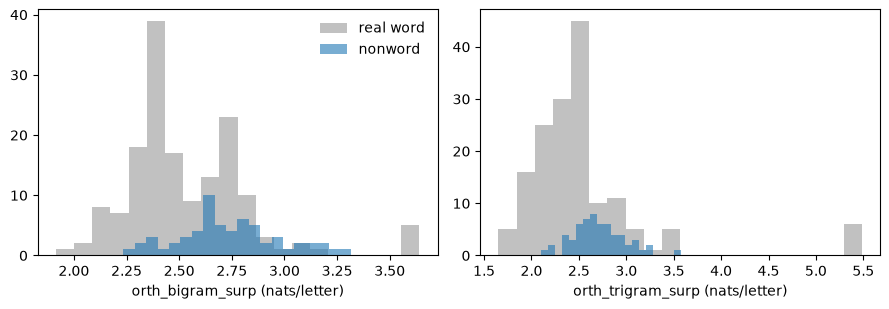

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, col in zip(axes, ["orth_bigram_surp", "orth_trigram_surp"]):
    for kind, color in [("real word", "0.6"), ("nonword", "C0")]:
        ax.hist(both.loc[both["kind"] == kind, col], bins=20, alpha=0.6, color=color, label=kind)
    ax.set_xlabel(f"{col} (nats/letter)")
axes[0].legend(frameon=False)
fig.tight_layout()

Short function words (*the*, *a*, *of*) are scored over only a few letters, so their means are noisy. That is
why the real-word distribution is wide.

The phonotactic counterpart (BLICK, `blick_word`) needs phones. None of these nonwords is in CMUdict, so it is
empty until hand phone labels are given (see `data/examples/nonwords/output/missing_phones.csv`).